### Embedded Methods for Feature Selection

Embedded methods perform feature selection during model training. The model learns which features are useful as part of its fitting process, rather than evaluating features only through a separate statistical test or repeatedly testing every possible subset.

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv')

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Feature Selection using LASSO  

**How it works :** LASSO (Least Absolute Shrinkage and Selection Operator) is a linear model trained with an L1 penalty. The penalty shrinks coefficient values, and some coefficients can become exactly zero. Features with non-zero coefficients remain in the model; zero-coefficient features are effectively excluded.

**Advantages**
- Can perform feature selection and model fitting together.
- Produces a sparse model by setting some coefficients to zero.
- Helps reduce overfitting when the regularization strength is chosen appropriately.

**Disadvantages**
- Requires feature scaling when features use different measurement scales.
- The selected features depend on the regularization parameter `alpha`.
- With highly correlated features, LASSO may select one feature and shrink another, making selection less stable.
- It is based on a linear relationship between the features and target, so it may miss non-linear patterns unless they are represented in the input features.

In [4]:
x_train, x_test, y_train, y_test = train_test_split(df.iloc[:, 0:-1], df.iloc[:, -1], test_size=0.2, random_state=1)

In [5]:
x_train.shape

(614, 8)

In [6]:
x_train.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
663,9,145,80,46,130,37.9,0.637,40
712,10,129,62,36,0,41.2,0.441,38
161,7,102,74,40,105,37.2,0.204,45
509,8,120,78,0,0,25.0,0.409,64
305,2,120,76,37,105,39.7,0.215,29


In [7]:
# scaling the data 
from sklearn.preprocessing import StandardScaler

cols = x_train.columns

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

x_train_scaled = pd.DataFrame(x_train_scaled, columns=cols)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=cols)

In [8]:
x_train_scaled

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,1.516591,0.750524,0.564756,1.652015,0.437496,0.795825,0.529526,0.567932
1,1.812018,0.244752,-0.347904,1.020973,-0.678474,1.228654,-0.069689,0.398450
2,0.925736,-0.608739,0.260536,1.273390,0.222886,0.704013,-0.794249,0.991638
3,1.221164,-0.039745,0.463350,-1.250779,-0.678474,-0.896139,-0.167519,2.601722
4,-0.551400,-0.039745,0.361943,1.084077,0.222886,1.031914,-0.760619,-0.364222
...,...,...,...,...,...,...,...,...
609,-0.551400,1.129853,0.260536,0.957869,3.098656,0.992566,-1.008254,-0.279481
610,0.925736,2.078175,-0.956345,0.831660,2.686605,0.271185,1.107339,0.059484
611,2.698300,0.149919,1.071790,-1.250779,-0.678474,1.517206,0.364436,0.737415
612,0.039454,1.572403,0.159129,-1.250779,-0.678474,1.543438,0.046486,-0.618446


In [9]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.01)

lasso.fit(x_train_scaled, y_train)

Lasso(alpha=0.01)

In [10]:
lasso.coef_

array([ 6.26290474e-02,  1.85968700e-01, -3.50258983e-02, -0.00000000e+00,
       -1.62558777e-04,  8.51781764e-02,  2.83810683e-02,  1.84611338e-02])

<Axes: >

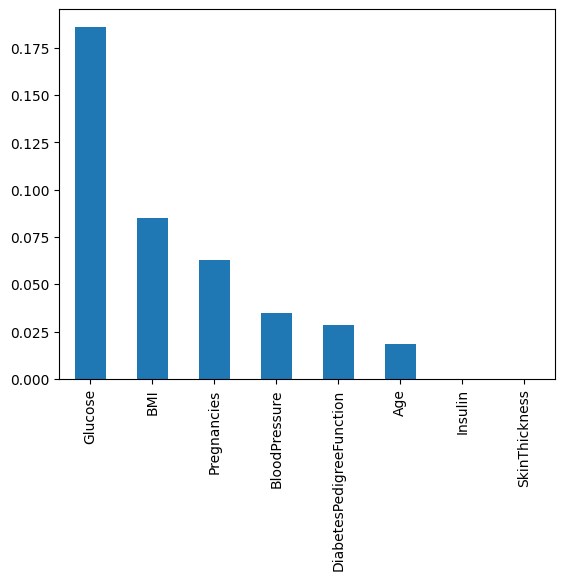

In [11]:
x = pd.Series(np.abs(lasso.coef_), index=cols)
x.sort_values(ascending=False).plot(kind='bar')

### Feature Selection using Decision Tree   

**How it works :** A Decision Tree learns rules by splitting the data. After training, `feature_importances_` reports how much each feature contributed to reducing impurity across the tree. Features with larger importance scores are considered more influential by that fitted tree.

**Advantages**
- Can capture non-linear relationships and feature interactions.
- Does not require feature scaling for a standard Decision Tree.
- Provides feature-importance scores that can be used for ranking or selection.

**Disadvantages**
- Importance scores can be unstable: small changes in the data may produce a different tree.
- Features with many possible split points can receive an advantage in some settings.
- Correlated features can share or distort importance, and impurity importance does not show whether a relationship is positive or negative.

In [12]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()

In [13]:
dt.fit(x_train, y_train)

DecisionTreeClassifier()

In [14]:
dt.feature_importances_

array([0.06180777, 0.28545099, 0.10287538, 0.04526501, 0.0430716 ,
       0.19115632, 0.11286689, 0.15750604])

<Axes: >

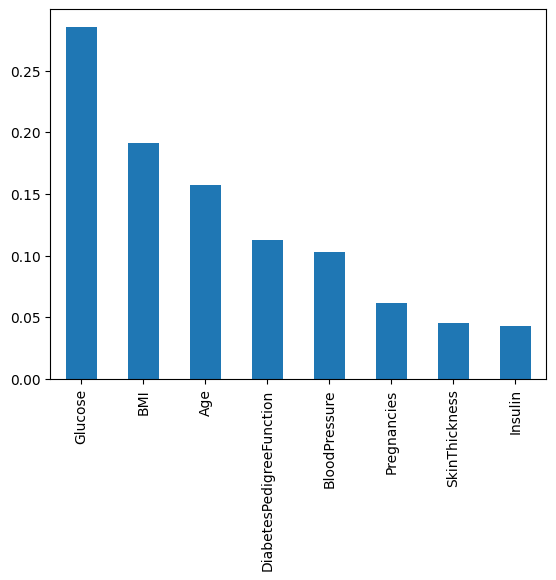

In [15]:
x = pd.Series(np.abs(dt.feature_importances_), index=cols)
x.sort_values(ascending=False).plot(kind='bar')

### SelectFromModel
 `SelectFromModel` is a scikit-learn feature-selection utility. It fits an estimator, reads its feature-importance values or coefficients, and keeps features that meet the chosen threshold. In this notebook, the estimator is a `DecisionTreeClassifier` and the threshold is `0.1`.

In [16]:
from sklearn.feature_selection import SelectFromModel

model = DecisionTreeClassifier()

sfm = SelectFromModel(model, threshold=0.1)

In [17]:
sfm.fit(x_train, y_train)

SelectFromModel(estimator=DecisionTreeClassifier(), threshold=0.1)

In [18]:
sfm.get_support(indices=True)

array([1, 2, 5, 6, 7])

In [19]:
sfm.feature_names_in_[sfm.get_support(indices=True)]

array(['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction',
       'Age'], dtype=object)

In [20]:
x_train_trans = sfm.transform(x_train)
x_train_trans = pd.DataFrame(x_train_trans,columns=sfm.feature_names_in_[sfm.get_support(indices=True)])
x_train_trans

,Glucose,BloodPressure,BMI,DiabetesPedigreeFunction,Age
0,145.0,80.0,37.9,0.637,40.0
1,129.0,62.0,41.2,0.441,38.0
2,102.0,74.0,37.2,0.204,45.0
3,120.0,78.0,25.0,0.409,64.0
4,120.0,76.0,39.7,0.215,29.0
...,...,...,...,...,...
609,157.0,74.0,39.4,0.134,30.0
610,187.0,50.0,33.9,0.826,34.0
611,126.0,90.0,43.4,0.583,42.0
612,171.0,72.0,43.6,0.479,26.0


### Key Takeaways

- **LASSO** selects features by shrinking some linear-model coefficients to zero.
- **Decision Tree feature importance** ranks features by their contribution to impurity reduction in the trained tree.
- **SelectFromModel** applies a threshold to an estimator's coefficients or importance scores to retain selected features.
- Embedded feature selection depends on the estimator, its settings, and the training data. Fit the selection process using training data only, then evaluate the final model on separate test data.